starting with compression before bitpacking and checking the sizes .

In [9]:
pip install zstandard brotli lz4 python-snappy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 31.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 35.1 MB/s eta 0:00:00:00:01
Note: you may need to restart the kernel to use updated packages.


In [11]:
import numpy as np
import time
import gzip
import zlib
import bz2
import lzma

import zstandard as zstd
import brotli
import lz4.frame
import snappy


# ============================================================
# INPUT
# ============================================================

FILE = "/home/<user>/iot_dataset/rpi_tm_model/rules.npy"

rules = np.load(FILE)

# Convert the array to raw bytes.
# IMPORTANT:
# We are NOT bit-packing here.
raw_data = rules.tobytes()

raw_size = len(raw_data)

print("=" * 70)
print("DATASET")
print("=" * 70)

print("Shape       :", rules.shape)
print("Dtype       :", rules.dtype)
print("Elements    :", rules.size)
print("Raw size    :", raw_size, "bytes")
print("Raw size MB :", raw_size / (1024**2))

print()


# ============================================================
# HELPER
# ============================================================

results = []


def benchmark(name, compress_func, decompress_func):

    # -----------------------------
    # Compression
    # -----------------------------

    start = time.perf_counter()

    compressed = compress_func(raw_data)

    compression_time = time.perf_counter() - start

    # -----------------------------
    # Decompression
    # -----------------------------

    start = time.perf_counter()

    decompressed = decompress_func(compressed)

    decompression_time = time.perf_counter() - start

    # -----------------------------
    # Verify losslessness
    # -----------------------------

    correct = decompressed == raw_data

    # -----------------------------
    # Statistics
    # -----------------------------

    compressed_size = len(compressed)

    saving = (1 - compressed_size / raw_size) * 100

    ratio = raw_size / compressed_size

    results.append({
        "Algorithm": name,
        "Raw_MB": raw_size / (1024**2),
        "Compressed_MB": compressed_size / (1024**2),
        "Compression_%": saving,
        "Ratio": ratio,
        "Compress_ms": compression_time * 1000,
        "Decompress_ms": decompression_time * 1000,
        "Lossless": correct
    })


# ============================================================
# 1. ZLIB
# ============================================================

for level in [1, 3, 6, 9]:

    benchmark(
        f"zlib-{level}",
        lambda data, level=level: zlib.compress(data, level),
        zlib.decompress
    )


# ============================================================
# 2. GZIP
# ============================================================

for level in [1, 3, 6, 9]:

    benchmark(
        f"gzip-{level}",
        lambda data, level=level: gzip.compress(data, compresslevel=level),
        gzip.decompress
    )


# ============================================================
# 3. BZIP2
# ============================================================

for level in [1, 5, 9]:

    benchmark(
        f"bzip2-{level}",
        lambda data, level=level: bz2.compress(data, compresslevel=level),
        bz2.decompress
    )


# ============================================================
# 4. LZMA
# ============================================================

for preset in [0, 3, 6, 9]:

    benchmark(
        f"lzma-{preset}",
        lambda data, preset=preset: lzma.compress(data, preset=preset),
        lzma.decompress
    )


# ============================================================
# 5. ZSTANDARD
# ============================================================

for level in [1, 3, 5, 7, 10]:

    compressor = zstd.ZstdCompressor(level=level)
    decompressor = zstd.ZstdDecompressor()

    benchmark(
        f"zstd-{level}",
        compressor.compress,
        decompressor.decompress
    )


# ============================================================
# 6. BROTLI
# ============================================================

for level in [1, 3, 5, 7, 9, 11]:

    benchmark(
        f"brotli-{level}",
        lambda data, level=level: brotli.compress(data, quality=level),
        brotli.decompress
    )


# ============================================================
# 7. LZ4
# ============================================================

for level in [0, 3, 9, 12]:

    benchmark(
        f"lz4-{level}",
        lambda data, level=level: lz4.frame.compress(
            data,
            compression_level=level
        ),
        lz4.frame.decompress
    )


# ============================================================
# 8. SNAPPY
# ============================================================

benchmark(
    "snappy",
    snappy.compress,
    snappy.uncompress
)


# ============================================================
# RESULTS
# ============================================================

import pandas as pd

df = pd.DataFrame(results)

df = df.sort_values(
    by="Compressed_MB",
    ascending=True
)

print()
print("=" * 100)
print("RESULTS — SORTED BY COMPRESSED SIZE")
print("=" * 100)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

DATASET
Shape       : (6, 6000, 526)
Dtype       : uint8
Elements    : 18936000
Raw size    : 18936000 bytes
Raw size MB : 18.05877685546875


RESULTS — SORTED BY COMPRESSED SIZE
Algorithm  Raw_MB  Compressed_MB  Compression_%  Ratio  Compress_ms  Decompress_ms  Lossless
brotli-11  18.059          0.640         96.455 28.210    27184.691         20.076      True
  bzip2-9  18.059          0.659         96.351 27.407      517.423        191.047      True
  bzip2-5  18.059          0.676         96.256 26.707      493.815        157.452      True
   lzma-6  18.059          0.731         95.952 24.701     3953.679         40.398      True
   lzma-9  18.059          0.733         95.940 24.632     4150.622         55.970      True
  bzip2-1  18.059          0.770         95.738 23.462      424.711        134.651      True
 brotli-9  18.059          0.890         95.070 20.283      550.274         16.911      True
   zlib-9  18.059          0.908         94.971 19.887     5478.601         2

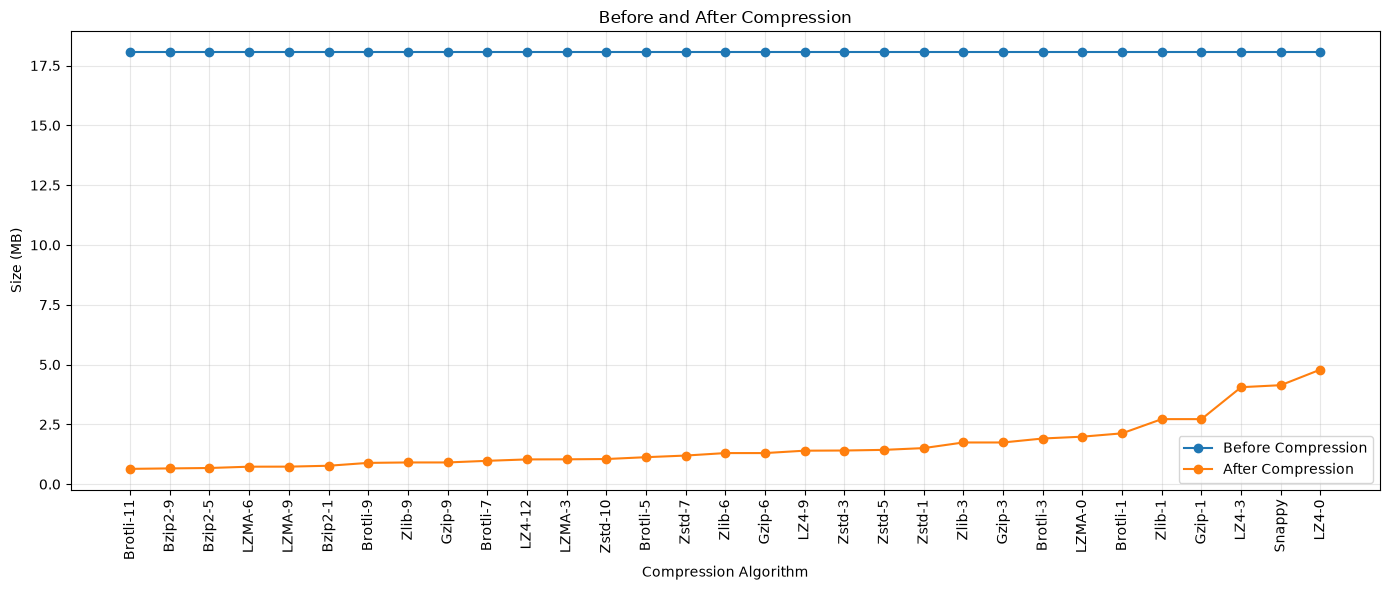

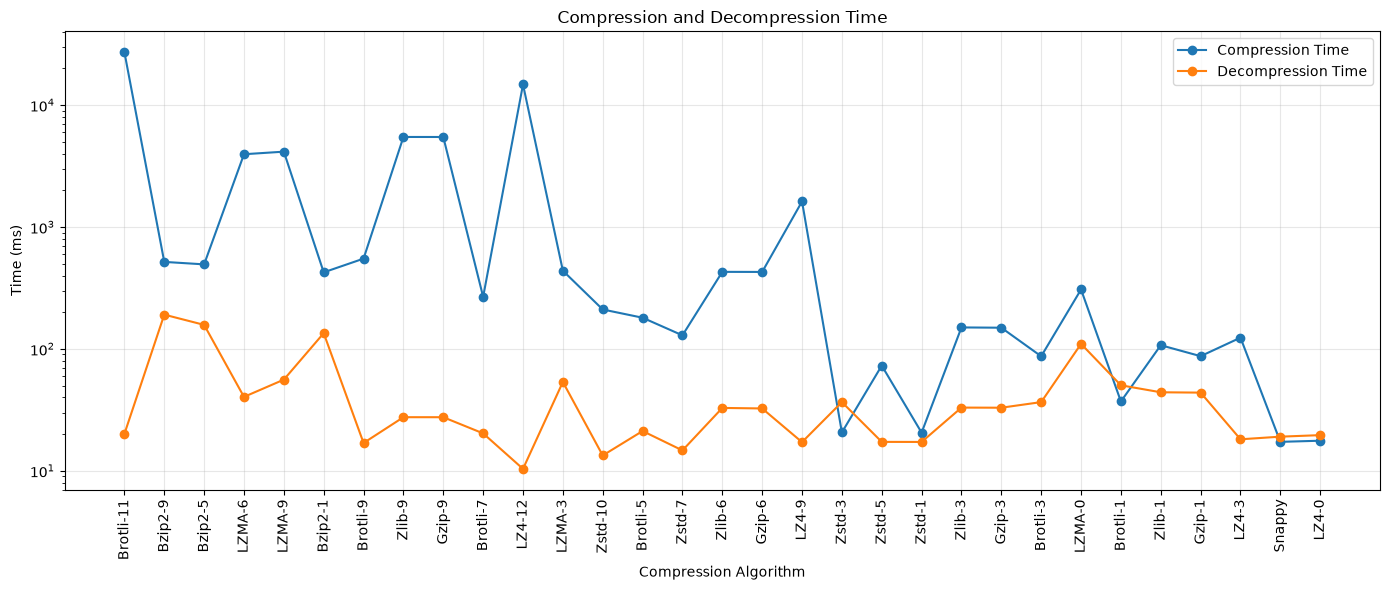

In [14]:
import matplotlib.pyplot as plt

algorithms = [
    "Brotli-11", "Bzip2-9", "Bzip2-5", "LZMA-6", "LZMA-9",
    "Bzip2-1", "Brotli-9", "Zlib-9", "Gzip-9", "Brotli-7",
    "LZ4-12", "LZMA-3", "Zstd-10", "Brotli-5", "Zstd-7",
    "Zlib-6", "Gzip-6", "LZ4-9", "Zstd-3", "Zstd-5",
    "Zstd-1", "Zlib-3", "Gzip-3", "Brotli-3", "LZMA-0",
    "Brotli-1", "Zlib-1", "Gzip-1", "LZ4-3", "Snappy",
    "LZ4-0"
]

compressed_MB = [
    0.640, 0.659, 0.676, 0.731, 0.733,
    0.770, 0.890, 0.908, 0.908, 0.976,
    1.035, 1.039, 1.051, 1.128, 1.196,
    1.300, 1.300, 1.400, 1.407, 1.434,
    1.508, 1.743, 1.743, 1.909, 1.986,
    2.125, 2.719, 2.719, 4.054, 4.138,
    4.791
]

compression_time = [
    27184.691, 517.423, 493.815, 3953.679, 4150.622,
    424.711, 550.274, 5478.601, 5475.845, 267.349,
    14767.858, 438.039, 210.624, 180.244, 129.212,
    428.663, 427.984, 1619.711, 20.643, 72.951,
    20.562, 150.038, 149.242, 86.983, 307.227,
    37.059, 107.206, 87.180, 123.689, 17.282,
    17.654
]

decompression_time = [
    20.076, 191.047, 157.452, 40.398, 55.970,
    134.651, 16.911, 27.528, 27.522, 20.278,
    10.374, 53.536, 13.359, 21.194, 14.700,
    32.798, 32.470, 17.187, 36.613, 17.270,
    17.250, 33.008, 32.931, 36.613, 109.971,
    50.299, 44.074, 43.794, 18.136, 19.058,
    19.616
]

raw_size = 18.05877685546875

x = range(len(algorithms))


# ============================================================
# GRAPH 1 — BEFORE VS AFTER COMPRESSION
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    x,
    [raw_size] * len(algorithms),
    marker='o',
    label='Before Compression'
)

plt.plot(
    x,
    compressed_MB,
    marker='o',
    label='After Compression'
)

plt.xticks(x, algorithms, rotation=90)
plt.ylabel("Size (MB)")
plt.xlabel("Compression Algorithm")
plt.title("Before and After Compression")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 2 — COMPRESSION VS DECOMPRESSION TIME
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    x,
    compression_time,
    marker='o',
    label='Compression Time'
)

plt.plot(
    x,
    decompression_time,
    marker='o',
    label='Decompression Time'
)

plt.xticks(x, algorithms, rotation=90)
plt.ylabel("Time (ms)")
plt.xlabel("Compression Algorithm")
plt.title("Compression and Decompression Time")

# Log scale because compression times vary enormously
plt.yscale("log")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
import numpy as np

# Total processing time
total_time = np.array(compression_time) + np.array(decompression_time)

# Sort by total time: smallest → largest
order = np.argsort(total_time)

print("Algorithms in increasing order of total compression + decompression time")
print("-" * 75)
print(f"{'Algorithm':<15} {'Total Time (ms)':>18} {'Compressed Size (MB)':>22}")
print("-" * 75)

for i in order:
    print(
        f"{algorithms[i]:<15} "
        f"{total_time[i]:>18.3f} "
        f"{compressed_MB[i]:>22.3f}"
    )

Algorithms in increasing order of total compression + decompression time
---------------------------------------------------------------------------
Algorithm          Total Time (ms)   Compressed Size (MB)
---------------------------------------------------------------------------
Snappy                      36.340                  4.138
LZ4-0                       37.270                  4.791
Zstd-1                      37.812                  1.508
Zstd-3                      57.256                  1.407
Brotli-1                    87.358                  2.125
Zstd-5                      90.221                  1.434
Brotli-3                   123.596                  1.909
Gzip-1                     130.974                  2.719
LZ4-3                      141.825                  4.054
Zstd-7                     143.912                  1.196
Zlib-1                     151.280                  2.719
Gzip-3                     182.173                  1.743
Zlib-3               

for bitpacked

In [17]:
import numpy as np
import time
import gzip
import zlib
import bz2
import lzma
import pandas as pd

import zstandard as zstd
import brotli
import lz4.frame
import snappy


# ============================================================
# INPUT — BIT-PACKED DATA
# ============================================================

FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"

rules = np.load(FILE)

# IMPORTANT:
# We compress the packed bytes directly.
raw_data = rules.tobytes()

raw_size = len(raw_data)

print("=" * 70)
print("BIT-PACKED DATASET")
print("=" * 70)

print("Shape       :", rules.shape)
print("Dtype       :", rules.dtype)
print("Raw size    :", raw_size, "bytes")
print("Raw size MB :", raw_size / (1024**2))

print()


# ============================================================
# BENCHMARK FUNCTION
# ============================================================

results = []


def benchmark(name, compress_func, decompress_func):

    # Compression
    start = time.perf_counter()
    compressed = compress_func(raw_data)
    compression_time = time.perf_counter() - start

    # Decompression
    start = time.perf_counter()
    decompressed = decompress_func(compressed)
    decompression_time = time.perf_counter() - start

    # Lossless verification
    lossless = decompressed == raw_data

    compressed_size = len(compressed)

    compression_percent = (
        1 - compressed_size / raw_size
    ) * 100

    ratio = raw_size / compressed_size

    results.append({
        "Algorithm": name,
        "Raw_MB": raw_size / (1024**2),
        "Compressed_MB": compressed_size / (1024**2),
        "Compression_%": compression_percent,
        "Ratio": ratio,
        "Compress_ms": compression_time * 1000,
        "Decompress_ms": decompression_time * 1000,
        "Total_ms": (
            compression_time + decompression_time
        ) * 1000,
        "Lossless": lossless
    })


# ============================================================
# ZLIB
# ============================================================

for level in [1, 3, 6, 9]:

    benchmark(
        f"zlib-{level}",
        lambda data, level=level:
            zlib.compress(data, level),
        zlib.decompress
    )


# ============================================================
# GZIP
# ============================================================

for level in [1, 3, 6, 9]:

    benchmark(
        f"gzip-{level}",
        lambda data, level=level:
            gzip.compress(data, compresslevel=level),
        gzip.decompress
    )


# ============================================================
# BZIP2
# ============================================================

for level in [1, 5, 9]:

    benchmark(
        f"bzip2-{level}",
        lambda data, level=level:
            bz2.compress(data, compresslevel=level),
        bz2.decompress
    )


# ============================================================
# LZMA
# ============================================================

for level in [0, 3, 6, 9]:

    benchmark(
        f"lzma-{level}",
        lambda data, level=level:
            lzma.compress(data, preset=level),
        lzma.decompress
    )


# ============================================================
# ZSTANDARD
# ============================================================

for level in [1, 3, 5, 7, 10]:

    compressor = zstd.ZstdCompressor(level=level)
    decompressor = zstd.ZstdDecompressor()

    benchmark(
        f"zstd-{level}",
        compressor.compress,
        decompressor.decompress
    )


# ============================================================
# BROTLI
# ============================================================

for level in [1, 3, 5, 7, 9, 11]:

    benchmark(
        f"brotli-{level}",
        lambda data, level=level:
            brotli.compress(data, quality=level),
        brotli.decompress
    )


# ============================================================
# LZ4
# ============================================================

for level in [0, 3, 9, 12]:

    benchmark(
        f"lz4-{level}",
        lambda data, level=level:
            lz4.frame.compress(
                data,
                compression_level=level
            ),
        lz4.frame.decompress
    )


# ============================================================
# SNAPPY
# ============================================================

benchmark(
    "snappy",
    snappy.compress,
    snappy.uncompress
)


# ============================================================
# RESULTS
# ============================================================

df = pd.DataFrame(results)

# Sort by total compression + decompression time
df = df.sort_values("Total_ms")

print("=" * 100)
print("BIT-PACKED RESULTS — SORTED BY TOTAL PROCESSING TIME")
print("=" * 100)

print(
    df[
        [
            "Algorithm",
            "Compressed_MB",
            "Compression_%",
            "Compress_ms",
            "Decompress_ms",
            "Total_ms",
            "Lossless"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

BIT-PACKED DATASET
Shape       : (6, 6000, 66)
Dtype       : uint8
Raw size    : 2376000 bytes
Raw size MB : 2.26593017578125

BIT-PACKED RESULTS — SORTED BY TOTAL PROCESSING TIME
Algorithm  Compressed_MB  Compression_%  Compress_ms  Decompress_ms  Total_ms  Lossless
    lz4-0          0.971         57.162        3.131          0.689     3.819      True
   snappy          0.956         57.797        3.502          1.295     4.797      True
   zstd-1          0.718         68.305        5.023          1.699     6.722      True
   zstd-3          0.694         69.367        6.209          1.743     7.952      True
 brotli-1          0.754         66.706        7.732          5.371    13.103      True
   zstd-5          0.686         69.723       15.225          2.239    17.463      True
    lz4-3          0.739         67.368       19.341          0.615    19.956      True
 brotli-3          0.688         69.623       16.581          4.655    21.235      True
   zstd-7          0.650    


BIT-PACKED DATA
Algorithm           Compressed MB       Compress ms       Decompress ms       Total ms
--------------------------------------------------------------------------------
lz4-0                       0.971             3.131               0.689          3.820
snappy                      0.956             3.502               1.295          4.797
zstd-1                      0.718             5.023               1.699          6.722
zstd-3                      0.694             6.209               1.743          7.952
brotli-1                    0.754             7.732               5.371         13.103
zstd-5                      0.686            15.225               2.239         17.464
lz4-3                       0.739            19.341               0.615         19.956
brotli-3                    0.688            16.581               4.655         21.236
zstd-7                      0.650            23.720               1.688         25.408
gzip-1                      0.81

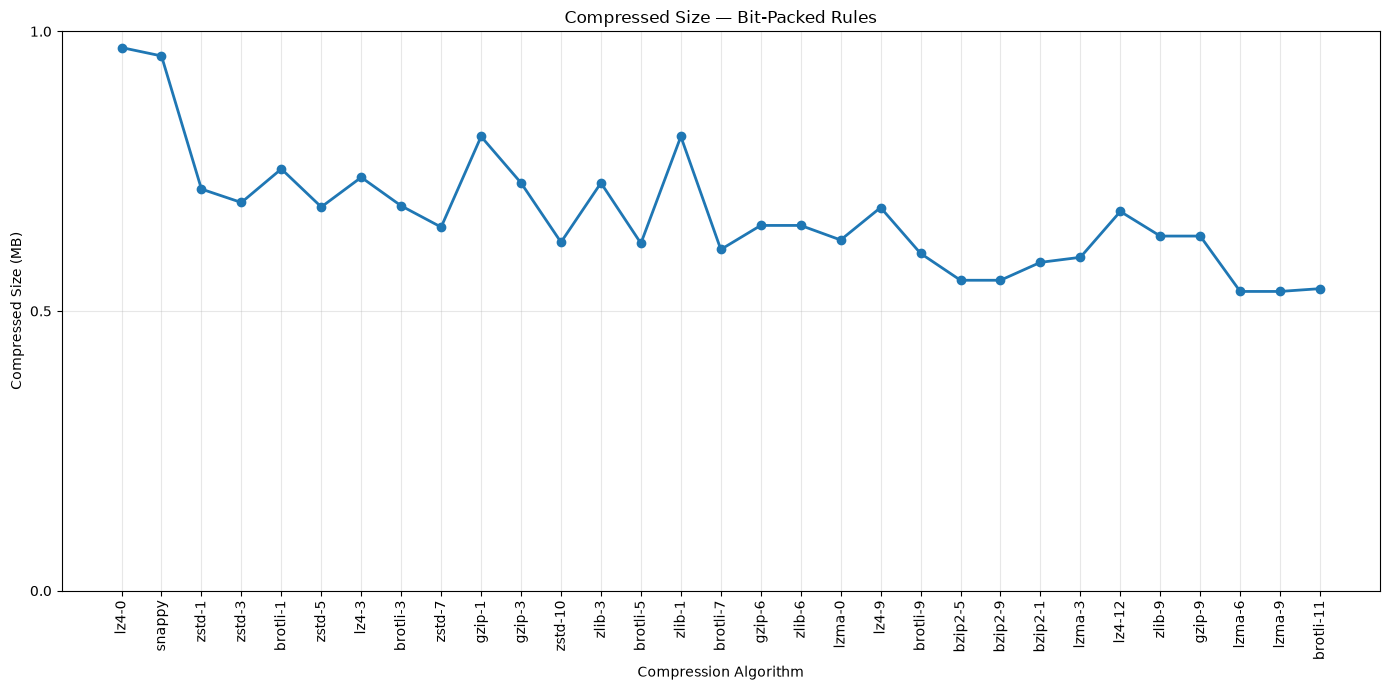

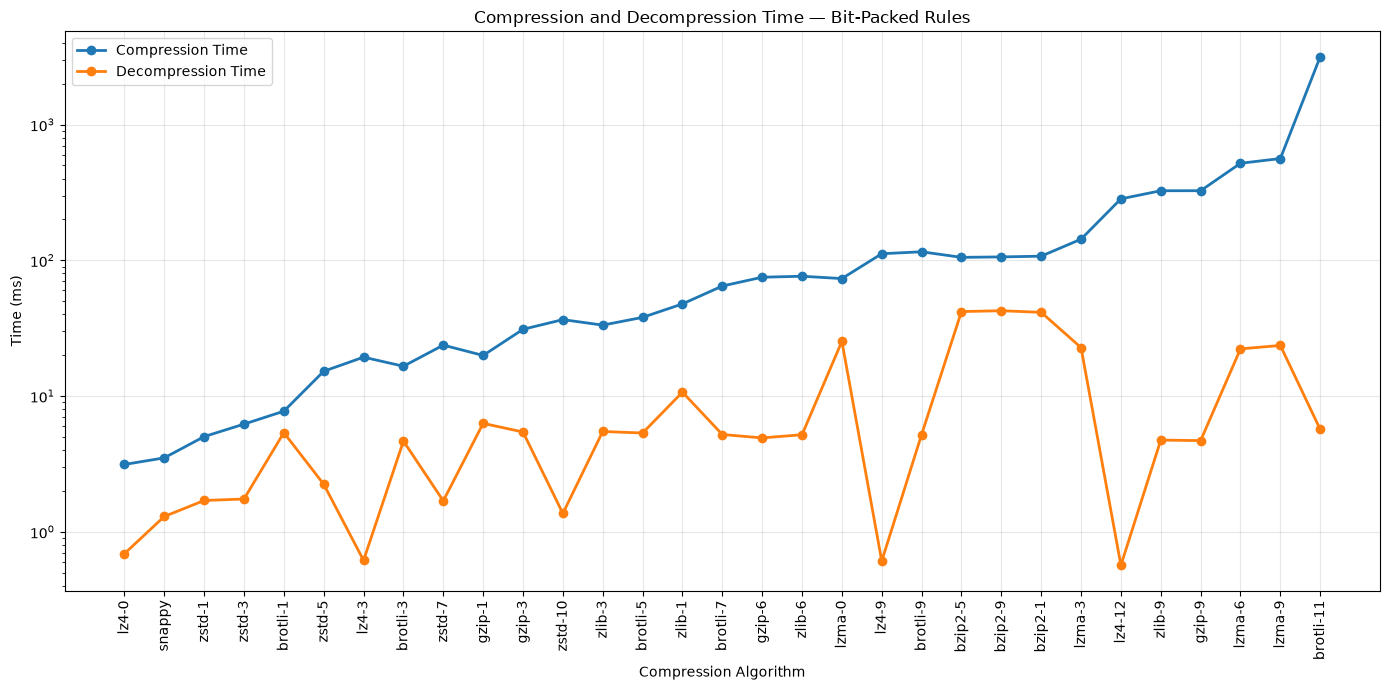

In [19]:
import numpy as np
import matplotlib.pyplot as plt

algorithms = [
    "lz4-0", "snappy", "zstd-1", "zstd-3", "brotli-1",
    "zstd-5", "lz4-3", "brotli-3", "zstd-7", "gzip-1",
    "gzip-3", "zstd-10", "zlib-3", "brotli-5", "zlib-1",
    "brotli-7", "gzip-6", "zlib-6", "lzma-0", "lz4-9",
    "brotli-9", "bzip2-5", "bzip2-9", "bzip2-1", "lzma-3",
    "lz4-12", "zlib-9", "gzip-9", "lzma-6", "lzma-9",
    "brotli-11"
]

compressed_MB = [
    0.971, 0.956, 0.718, 0.694, 0.754,
    0.686, 0.739, 0.688, 0.650, 0.812,
    0.729, 0.623, 0.729, 0.621, 0.812,
    0.610, 0.653, 0.653, 0.627, 0.685,
    0.603, 0.555, 0.555, 0.587, 0.596,
    0.678, 0.634, 0.634, 0.535, 0.535,
    0.540
]

compression_time = [
    3.131, 3.502, 5.023, 6.209, 7.732,
    15.225, 19.341, 16.581, 23.720, 19.907,
    31.024, 36.566, 33.308, 37.991, 47.731,
    64.655, 75.089, 76.341, 73.383, 111.839,
    115.628, 105.180, 105.958, 107.312, 143.172,
    283.828, 325.695, 325.816, 519.052, 562.258,
    3163.415
]

decompression_time = [
    0.689, 1.295, 1.699, 1.743, 5.371,
    2.239, 0.615, 4.655, 1.688, 6.290,
    5.430, 1.364, 5.479, 5.340, 10.678,
    5.205, 4.914, 5.186, 25.280, 0.608,
    5.201, 41.927, 42.517, 41.382, 22.749,
    0.566, 4.735, 4.694, 22.266, 23.587,
    5.674
]

raw_MB = 2.26593017578125

# ============================================================
# TOTAL TIME
# ============================================================

compression_time = np.array(compression_time)
decompression_time = np.array(decompression_time)
compressed_MB = np.array(compressed_MB)

total_time = compression_time + decompression_time


# ============================================================
# PRINT RESULTS
# ============================================================

print("\nBIT-PACKED DATA")
print("=" * 80)

print(
    f"{'Algorithm':<15}"
    f"{'Compressed MB':>18}"
    f"{'Compress ms':>18}"
    f"{'Decompress ms':>20}"
    f"{'Total ms':>15}"
)

print("-" * 80)

for i in range(len(algorithms)):
    print(
        f"{algorithms[i]:<15}"
        f"{compressed_MB[i]:>18.3f}"
        f"{compression_time[i]:>18.3f}"
        f"{decompression_time[i]:>20.3f}"
        f"{total_time[i]:>15.3f}"
    )


# ============================================================
# SORT BY TOTAL TIME
# ============================================================

order = np.argsort(total_time)

print("\n\nINCREASING ORDER OF COMPRESSION + DECOMPRESSION TIME")
print("=" * 75)

print(
    f"{'Algorithm':<15}"
    f"{'Compressed MB':>20}"
    f"{'Total Time ms':>20}"
)

print("-" * 75)

for i in order:
    print(
        f"{algorithms[i]:<15}"
        f"{compressed_MB[i]:>20.3f}"
        f"{total_time[i]:>20.3f}"
    )


# ============================================================
# GRAPH 1 — COMPRESSED SIZE
# ============================================================

plt.figure(figsize=(14, 7))

plt.plot(
    algorithms,
    compressed_MB,
    marker="o",
    linewidth=2
)

plt.xlabel("Compression Algorithm")
plt.ylabel("Compressed Size (MB)")
plt.title("Compressed Size — Bit-Packed Rules")

plt.xticks(rotation=90)

# 0.5 MB steps
plt.yticks(np.arange(0, 1.01, 0.5))

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 2 — COMPRESSION + DECOMPRESSION TIME
# ============================================================

plt.figure(figsize=(14, 7))

plt.plot(
    algorithms,
    compression_time,
    marker="o",
    linewidth=2,
    label="Compression Time"
)

plt.plot(
    algorithms,
    decompression_time,
    marker="o",
    linewidth=2,
    label="Decompression Time"
)

plt.xlabel("Compression Algorithm")
plt.ylabel("Time (ms)")
plt.title("Compression and Decompression Time — Bit-Packed Rules")

plt.xticks(rotation=90)

# Log scale because Brotli-11 is much slower
plt.yscale("log")

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

testing for sparse encoding and trying it out

In [1]:
import numpy as np
import time
import struct

# ============================================================
# CONFIG
# ============================================================

FILE = "/home/<user>/iot_dataset/rpi_tm_model/rules.npy"

rules = np.load(FILE)

assert rules.dtype == np.uint8
assert np.all((rules == 0) | (rules == 1))

ORIGINAL_BYTES = rules.nbytes

print("=" * 80)
print("ORIGINAL DATASET")
print("=" * 80)
print("Shape       :", rules.shape)
print("Dtype       :", rules.dtype)
print("Raw bytes   :", ORIGINAL_BYTES)
print("Raw MB      :", ORIGINAL_BYTES / (1024**2))
print("Ones        :", np.count_nonzero(rules))
print("Zeros       :", rules.size - np.count_nonzero(rules))
print("Density     :", np.count_nonzero(rules) / rules.size * 100, "%")
print("Sparsity    :", np.count_nonzero(rules == 0) / rules.size * 100, "%")


# ============================================================
# HELPER
# ============================================================

def report(name, encoded_bytes, encode_ms, decode_ms, correct):

    ratio = ORIGINAL_BYTES / encoded_bytes
    reduction = (1 - encoded_bytes / ORIGINAL_BYTES) * 100

    print(
        f"{name:<25}"
        f"{encoded_bytes / (1024**2):>12.4f} MB"
        f"{ratio:>12.3f}x"
        f"{reduction:>12.2f}%"
        f"{encode_ms:>14.3f}"
        f"{decode_ms:>14.3f}"
        f"{encode_ms + decode_ms:>14.3f}"
        f"{str(correct):>12}"
    )


# ============================================================
# 1. COO / POSITIONAL ENCODING
# ============================================================
#
# Store the flat positions of every 1.
#
# Example:
#
# 00100101
#
# ones = [2, 5, 7]
#
# Store:
#   [2, 5, 7]
#
# Since total elements = 18,936,000, uint32 is sufficient.
# ============================================================

def coo_encode(x):

    positions = np.flatnonzero(x)

    return positions.astype(np.uint32)


def coo_decode(encoded, shape):

    result = np.zeros(np.prod(shape), dtype=np.uint8)

    result[encoded] = 1

    return result.reshape(shape)


# ============================================================
# 2. CSR
# ============================================================
#
# Treat the dataset as:
#
#       rows = 6 * 6000
#       cols = 526
#
# Shape:
#       (36000, 526)
#
# CSR stores:
#
#   data
#   column_indices
#   row_ptr
#
# Because data is binary, data itself is implicit = 1.
#
# ============================================================

def csr_encode(x):

    matrix = x.reshape(-1, x.shape[-1])

    row_count, col_count = matrix.shape

    row_ptr = np.zeros(row_count + 1, dtype=np.uint32)

    positions = []

    count = 0

    for r in range(row_count):

        cols = np.flatnonzero(matrix[r])

        positions.append(cols.astype(np.uint16))

        count += len(cols)

        row_ptr[r + 1] = count

    if positions:
        col_indices = np.concatenate(positions)
    else:
        col_indices = np.array([], dtype=np.uint16)

    return col_indices, row_ptr


def csr_decode(encoded, shape):

    col_indices, row_ptr = encoded

    rows = np.prod(shape[:-1])
    cols = shape[-1]

    result = np.zeros((rows, cols), dtype=np.uint8)

    for r in range(rows):

        start = row_ptr[r]
        end = row_ptr[r + 1]

        result[r, col_indices[start:end]] = 1

    return result.reshape(shape)


# ============================================================
# 3. CSC
# ============================================================
#
# Same logical matrix:
#
#       (36000, 526)
#
# CSC stores:
#
#   row_indices
#   col_ptr
#
# Since there are 36000 rows, row indices require uint16.
# ============================================================

def csc_encode(x):

    matrix = x.reshape(-1, x.shape[-1])

    rows, cols = matrix.shape

    col_ptr = np.zeros(cols + 1, dtype=np.uint32)

    positions = []

    count = 0

    for c in range(cols):

        rows_with_one = np.flatnonzero(matrix[:, c])

        positions.append(rows_with_one.astype(np.uint16))

        count += len(rows_with_one)

        col_ptr[c + 1] = count

    if positions:
        row_indices = np.concatenate(positions)
    else:
        row_indices = np.array([], dtype=np.uint16)

    return row_indices, col_ptr


def csc_decode(encoded, shape):

    row_indices, col_ptr = encoded

    rows = np.prod(shape[:-1])
    cols = shape[-1]

    result = np.zeros((rows, cols), dtype=np.uint8)

    for c in range(cols):

        start = col_ptr[c]
        end = col_ptr[c + 1]

        result[row_indices[start:end], c] = 1

    return result.reshape(shape)


# ============================================================
# 4. RLE
# ============================================================
#
# Binary RLE.
#
# Instead of storing:
#
#   0 0 0 1 1 0 0 1
#
# store run lengths:
#
#   [3, 2, 2, 1]
#
# plus the starting value.
#
# Since values alternate, we don't need to store the value
# of every run.
# ============================================================

def rle_encode(x):

    flat = x.ravel()

    if len(flat) == 0:
        return np.array([], dtype=np.uint32), np.uint8(0)

    changes = np.flatnonzero(flat[1:] != flat[:-1]) + 1

    boundaries = np.concatenate(([0], changes, [len(flat)]))

    lengths = np.diff(boundaries).astype(np.uint32)

    start_value = np.uint8(flat[0])

    return lengths, start_value


def rle_decode(encoded, shape):

    lengths, start_value = encoded

    total = int(np.sum(lengths))

    result = np.empty(total, dtype=np.uint8)

    pos = 0
    value = int(start_value)

    for length in lengths:

        end = pos + int(length)

        result[pos:end] = value

        value ^= 1

        pos = end

    return result.reshape(shape)


# ============================================================
# 5. GAP ENCODING + VARINT
# ============================================================
#
# First obtain positions of 1s:
#
#   [100, 105, 110, 115]
#
# Instead of storing:
#
#   100,105,110,115
#
# store:
#
#   100,5,5,5
#
# Then encode each integer using unsigned LEB128 / Varint.
#
# Small numbers require fewer bytes.
# ============================================================

def encode_varint(value):

    out = bytearray()

    value = int(value)

    while value >= 128:

        out.append((value & 0x7F) | 0x80)

        value >>= 7

    out.append(value)

    return bytes(out)


def decode_varints(data):

    values = []

    value = 0
    shift = 0

    for byte in data:

        byte = int(byte)

        value |= (byte & 0x7F) << shift

        if (byte & 0x80) == 0:

            values.append(value)

            value = 0
            shift = 0

        else:

            shift += 7

    return np.array(values, dtype=np.uint32)


def gap_encode(x):

    positions = np.flatnonzero(x).astype(np.uint32)

    if len(positions) == 0:
        return b""

    gaps = np.empty_like(positions)

    gaps[0] = positions[0]

    gaps[1:] = positions[1:] - positions[:-1]

    encoded = bytearray()

    for gap in gaps:

        encoded.extend(encode_varint(gap))

    return bytes(encoded)


def gap_decode(encoded, shape):

    gaps = decode_varints(encoded)

    result = np.zeros(np.prod(shape), dtype=np.uint8)

    if len(gaps) == 0:
        return result.reshape(shape)

    positions = np.cumsum(gaps, dtype=np.uint64)

    result[positions.astype(np.int64)] = 1

    return result.reshape(shape)


# ============================================================
# 6. BLOCK-SPARSE
# ============================================================
#
# Divide the logical data into blocks of 64 elements.
#
# Example:
#
# block:
#
#   0000000000000000
#
# is omitted completely.
#
# If a block contains at least one 1, store:
#
#   block index
#   64-bit block contents
#
# Since we are NOT using bit-packing for the original dataset,
# this is a sparse representation built directly from uint8
# logical values.
# ============================================================

BLOCK_SIZE = 64


def block_sparse_encode(x):

    flat = x.ravel()

    total = len(flat)

    num_blocks = (total + BLOCK_SIZE - 1) // BLOCK_SIZE

    block_indices = []
    block_data = []

    for b in range(num_blocks):

        start = b * BLOCK_SIZE
        end = min(start + BLOCK_SIZE, total)

        block = flat[start:end]

        if np.any(block):

            block_indices.append(b)

            # Store the logical 64-bit block as a Python integer.
            value = 0

            for i, bit in enumerate(block):

                if bit:
                    value |= (1 << i)

            block_data.append(value)

    block_indices = np.array(block_indices, dtype=np.uint32)

    block_data = np.array(block_data, dtype=np.uint64)

    return block_indices, block_data


def block_sparse_decode(encoded, shape):

    block_indices, block_data = encoded

    total = np.prod(shape)

    result = np.zeros(total, dtype=np.uint8)

    for block_index, block_value in zip(block_indices, block_data):

        start = int(block_index) * BLOCK_SIZE

        end = min(start + BLOCK_SIZE, total)

        length = end - start

        value = int(block_value)

        for i in range(length):

            result[start + i] = (value >> i) & 1

    return result.reshape(shape)


# ============================================================
# BENCHMARK
# ============================================================

print()
print("=" * 150)
print(
    f"{'Method':<25}"
    f"{'Size':>12}"
    f"{'Ratio':>12}"
    f"{'Reduction':>12}"
    f"{'Encode ms':>14}"
    f"{'Decode ms':>14}"
    f"{'Total ms':>14}"
    f"{'Correct':>12}"
)
print("=" * 150)


# ------------------------------------------------------------
# COO
# ------------------------------------------------------------

t0 = time.perf_counter()

coo = coo_encode(rules)

t1 = time.perf_counter()

coo_decoded = coo_decode(coo, rules.shape)

t2 = time.perf_counter()

coo_size = coo.nbytes

report(
    "COO",
    coo_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    np.array_equal(rules, coo_decoded)
)


# ------------------------------------------------------------
# CSR
# ------------------------------------------------------------

t0 = time.perf_counter()

csr = csr_encode(rules)

t1 = time.perf_counter()

csr_decoded = csr_decode(csr, rules.shape)

t2 = time.perf_counter()

csr_size = csr[0].nbytes + csr[1].nbytes

report(
    "CSR",
    csr_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    np.array_equal(rules, csr_decoded)
)


# ------------------------------------------------------------
# CSC
# ------------------------------------------------------------

t0 = time.perf_counter()

csc = csc_encode(rules)

t1 = time.perf_counter()

csc_decoded = csc_decode(csc, rules.shape)

t2 = time.perf_counter()

csc_size = csc[0].nbytes + csc[1].nbytes

report(
    "CSC",
    csc_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    np.array_equal(rules, csc_decoded)
)


# ------------------------------------------------------------
# RLE
# ------------------------------------------------------------

t0 = time.perf_counter()

rle = rle_encode(rules)

t1 = time.perf_counter()

rle_decoded = rle_decode(rle, rules.shape)

t2 = time.perf_counter()

rle_size = rle[0].nbytes + rle[1].nbytes

report(
    "RLE",
    rle_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    np.array_equal(rules, rle_decoded)
)


# ------------------------------------------------------------
# GAP + VARINT
# ------------------------------------------------------------

t0 = time.perf_counter()

gap = gap_encode(rules)

t1 = time.perf_counter()

gap_decoded = gap_decode(gap, rules.shape)

t2 = time.perf_counter()

gap_size = len(gap)

report(
    "Gap + Varint",
    gap_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    np.array_equal(rules, gap_decoded)
)


# ------------------------------------------------------------
# BLOCK SPARSE
# ------------------------------------------------------------

t0 = time.perf_counter()

block = block_sparse_encode(rules)

t1 = time.perf_counter()

block_decoded = block_sparse_decode(block, rules.shape)

t2 = time.perf_counter()

block_size = block[0].nbytes + block[1].nbytes

report(
    "Block Sparse 64",
    block_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    np.array_equal(rules, block_decoded)
)


print("=" * 150)

ORIGINAL DATASET
Shape       : (6, 6000, 526)
Dtype       : uint8
Raw bytes   : 18936000
Raw MB      : 18.05877685546875
Ones        : 6055279
Zeros       : 12880721
Density     : 31.977603506548373 %
Sparsity    : 68.02239649345164 %

Method                           Size       Ratio   Reduction     Encode ms     Decode ms      Total ms     Correct
COO                           23.0991 MB       0.782x      -27.91%        43.883        19.652        63.534        True
CSR                           11.6869 MB       1.545x       35.28%       109.233        66.845       176.079        True
CSC                           11.5515 MB       1.563x       36.03%        57.147        19.735        76.882        True
RLE                           14.0719 MB       1.283x       22.08%        23.433      1228.614      1252.047        True
Gap + Varint                   5.7833 MB       3.123x       67.98%      1195.874       680.381      1876.255        True
Block Sparse 64                2.9960 MB   

for bit packed data 

ORIGINAL UNBIT-PACKED DATASET
Shape       : (6, 6000, 526)
Dtype       : uint8
Raw bytes   : 18936000
Raw MB      : 18.05877685546875
Elements    : 18936000
Ones        : 6055279
Zeros       : 12880721
Density     : 31.977603506548373
Sparsity    : 68.02239649345164

ALL LOSSLESS REPRESENTATIONS — SAME ORIGINAL INPUT
Method                        Bytes          MB       Ratio     Reduction     Encode ms     Decode ms      Total ms   Correct
-----------------------------------------------------------------------------------------------------------------------------
Original uint8           18,936,000     18.0588       1.000x         0.00%             -             -             -      True
Bit-packing               2,376,000      2.2659       7.970x        87.45%         2.263         1.691         3.953      True
Block Sparse 64           3,141,516      2.9960       6.028x        83.41%      1509.892      1334.586      2844.478      True
Gap + Varint              6,064,191      5.7833 

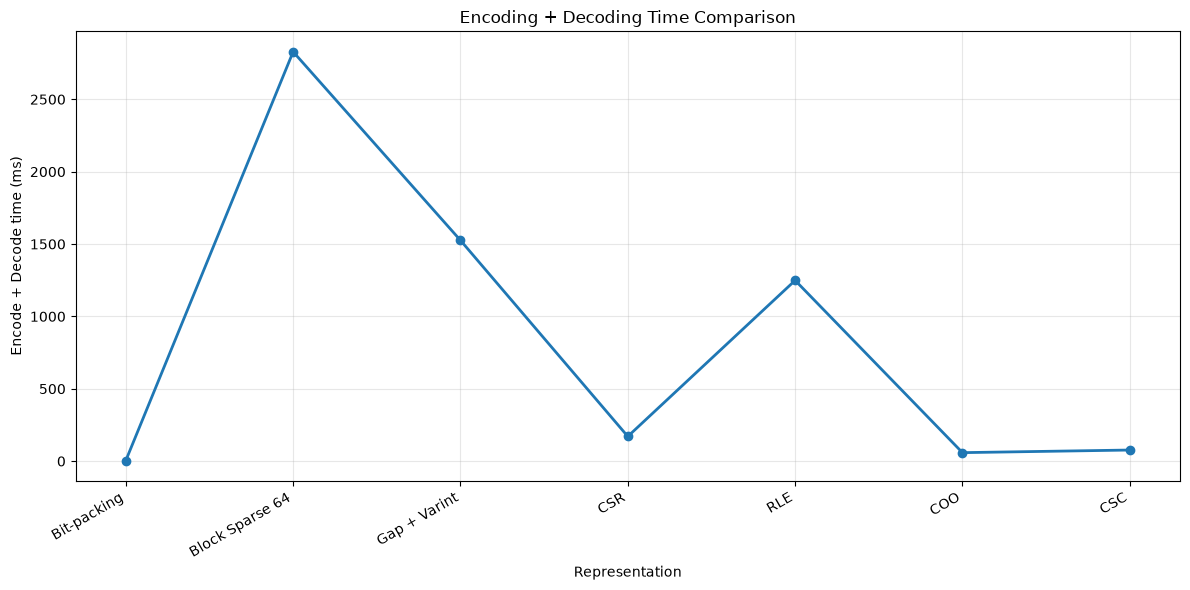

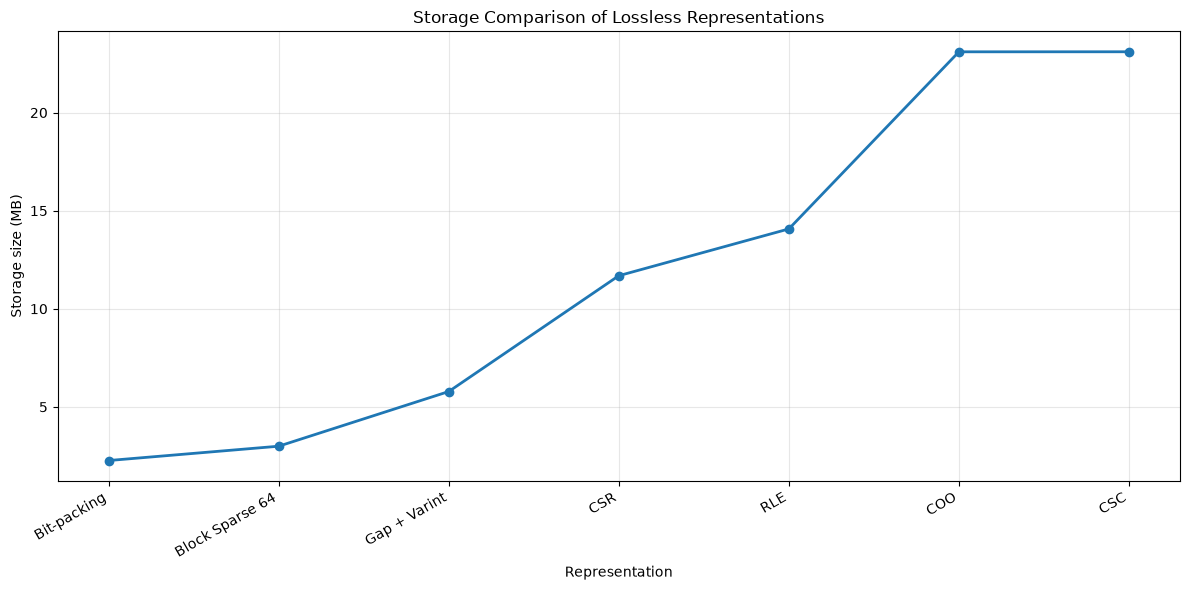

In [10]:
import numpy as np
import time
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================

RULES_FILE = "/home/<user>/iot_dataset/rpi_tm_model/rules.npy"

rules = np.load(RULES_FILE)

assert rules.dtype == np.uint8
assert rules.shape == (6, 6000, 526)

RAW_BYTES = rules.nbytes

print("=" * 110)
print("ORIGINAL UNBIT-PACKED DATASET")
print("=" * 110)

print("Shape       :", rules.shape)
print("Dtype       :", rules.dtype)
print("Raw bytes   :", RAW_BYTES)
print("Raw MB      :", RAW_BYTES / (1024**2))

ones = np.count_nonzero(rules)
zeros = rules.size - ones

print("Elements    :", rules.size)
print("Ones        :", ones)
print("Zeros       :", zeros)
print("Density     :", ones / rules.size * 100)
print("Sparsity    :", zeros / rules.size * 100)


# ============================================================
# RESULTS
# ============================================================

results = []


def add_result(
    name,
    encoded_size,
    encode_ms,
    decode_ms,
    decoded
):

    correct = np.array_equal(
        rules,
        decoded
    )

    ratio = RAW_BYTES / encoded_size

    reduction = (
        1 - encoded_size / RAW_BYTES
    ) * 100

    results.append({
        "Method": name,
        "Size_bytes": encoded_size,
        "Size_MB": encoded_size / (1024**2),
        "Ratio": ratio,
        "Reduction_%": reduction,
        "Encode_ms": encode_ms,
        "Decode_ms": decode_ms,
        "Total_ms": encode_ms + decode_ms,
        "Correct": correct
    })


# ============================================================
# 1. BIT-PACKING
# ============================================================

t0 = time.perf_counter()

packed = np.packbits(
    rules,
    axis=-1,
    bitorder="little"
)

t1 = time.perf_counter()

decoded = np.unpackbits(
    packed,
    axis=-1,
    bitorder="little"
)[..., :rules.shape[-1]]

t2 = time.perf_counter()

add_result(
    "Bit-packing",
    packed.nbytes,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# 2. COO
# ============================================================

def coo_encode(x):
    positions = np.flatnonzero(x)

    return positions.astype(
        np.uint32
    )


def coo_decode(encoded, shape):

    result = np.zeros(
        np.prod(shape),
        dtype=np.uint8
    )

    result[encoded] = 1

    return result.reshape(shape)


t0 = time.perf_counter()

coo = coo_encode(rules)

t1 = time.perf_counter()

decoded = coo_decode(
    coo,
    rules.shape
)

t2 = time.perf_counter()

add_result(
    "COO",
    coo.nbytes,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# 3. CSR
# ============================================================

def csr_encode(x):

    matrix = x.reshape(
        -1,
        x.shape[-1]
    )

    rows, cols = matrix.shape

    row_ptr = np.zeros(
        rows + 1,
        dtype=np.uint32
    )

    indices = []

    count = 0

    for r in range(rows):

        cols_with_one = np.flatnonzero(
            matrix[r]
        )

        indices.append(
            cols_with_one.astype(
                np.uint16
            )
        )

        count += len(cols_with_one)

        row_ptr[r + 1] = count

    col_indices = np.concatenate(
        indices
    )

    return col_indices, row_ptr


def csr_decode(encoded, shape):

    col_indices, row_ptr = encoded

    rows = np.prod(shape[:-1])
    cols = shape[-1]

    result = np.zeros(
        (rows, cols),
        dtype=np.uint8
    )

    for r in range(rows):

        start = row_ptr[r]
        end = row_ptr[r + 1]

        result[
            r,
            col_indices[start:end]
        ] = 1

    return result.reshape(shape)


t0 = time.perf_counter()

csr = csr_encode(rules)

t1 = time.perf_counter()

decoded = csr_decode(
    csr,
    rules.shape
)

t2 = time.perf_counter()

csr_size = (
    csr[0].nbytes +
    csr[1].nbytes
)

add_result(
    "CSR",
    csr_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# 4. CSC
# ============================================================

def csc_encode(x):

    matrix = x.reshape(
        -1,
        x.shape[-1]
    )

    rows, cols = matrix.shape

    col_ptr = np.zeros(
        cols + 1,
        dtype=np.uint32
    )

    indices = []

    count = 0

    for c in range(cols):

        rows_with_one = np.flatnonzero(
            matrix[:, c]
        )

        indices.append(
            rows_with_one.astype(
                np.uint32
            )
        )

        count += len(rows_with_one)

        col_ptr[c + 1] = count

    row_indices = np.concatenate(
        indices
    )

    return row_indices, col_ptr


def csc_decode(encoded, shape):

    row_indices, col_ptr = encoded

    rows = np.prod(shape[:-1])
    cols = shape[-1]

    result = np.zeros(
        (rows, cols),
        dtype=np.uint8
    )

    for c in range(cols):

        start = col_ptr[c]
        end = col_ptr[c + 1]

        result[
            row_indices[start:end],
            c
        ] = 1

    return result.reshape(shape)


t0 = time.perf_counter()

csc = csc_encode(rules)

t1 = time.perf_counter()

decoded = csc_decode(
    csc,
    rules.shape
)

t2 = time.perf_counter()

csc_size = (
    csc[0].nbytes +
    csc[1].nbytes
)

add_result(
    "CSC",
    csc_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# 5. RLE
# ============================================================

def rle_encode(x):

    flat = x.ravel()

    changes = np.flatnonzero(
        flat[1:] != flat[:-1]
    ) + 1

    boundaries = np.concatenate(
        ([0], changes, [len(flat)])
    )

    lengths = np.diff(
        boundaries
    ).astype(np.uint32)

    start_value = np.uint8(
        flat[0]
    )

    return lengths, start_value


def rle_decode(encoded, shape):

    lengths, start_value = encoded

    total = int(
        np.sum(lengths)
    )

    result = np.empty(
        total,
        dtype=np.uint8
    )

    pos = 0
    value = int(start_value)

    for length in lengths:

        end = pos + int(length)

        result[pos:end] = value

        value ^= 1

        pos = end

    return result.reshape(shape)


t0 = time.perf_counter()

rle = rle_encode(rules)

t1 = time.perf_counter()

decoded = rle_decode(
    rle,
    rules.shape
)

t2 = time.perf_counter()

rle_size = (
    rle[0].nbytes +
    rle[1].nbytes
)

add_result(
    "RLE",
    rle_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# 6. GAP + VARINT
# ============================================================

def encode_varint(value):

    output = bytearray()

    value = int(value)

    while value >= 128:

        output.append(
            (value & 0x7F) | 0x80
        )

        value >>= 7

    output.append(value)

    return output


def gap_encode(x):

    positions = np.flatnonzero(x)

    if len(positions) == 0:
        return b""

    gaps = np.empty_like(
        positions,
        dtype=np.uint32
    )

    gaps[0] = positions[0]

    gaps[1:] = (
        positions[1:]
        - positions[:-1]
    )

    output = bytearray()

    for gap in gaps:

        output.extend(
            encode_varint(gap)
        )

    return bytes(output)


def decode_varints(data):

    values = []

    value = 0
    shift = 0

    for byte in data:

        byte = int(byte)

        value |= (
            (byte & 0x7F)
            << shift
        )

        if not (byte & 0x80):

            values.append(value)

            value = 0
            shift = 0

        else:

            shift += 7

    return np.asarray(
        values,
        dtype=np.uint32
    )


def gap_decode(encoded, shape):

    gaps = decode_varints(
        encoded
    )

    total = np.prod(shape)

    result = np.zeros(
        total,
        dtype=np.uint8
    )

    if len(gaps) == 0:

        return result.reshape(shape)

    positions = np.cumsum(
        gaps,
        dtype=np.uint64
    )

    result[
        positions.astype(np.int64)
    ] = 1

    return result.reshape(shape)


t0 = time.perf_counter()

gap = gap_encode(rules)

t1 = time.perf_counter()

decoded = gap_decode(
    gap,
    rules.shape
)

t2 = time.perf_counter()

add_result(
    "Gap + Varint",
    len(gap),
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# 7. BLOCK SPARSE
# ============================================================

BLOCK_SIZE = 64


def block_sparse_encode(x):

    flat = x.ravel()

    total = len(flat)

    num_blocks = (
        total + BLOCK_SIZE - 1
    ) // BLOCK_SIZE

    block_indices = []
    block_values = []

    for b in range(num_blocks):

        start = b * BLOCK_SIZE

        end = min(
            start + BLOCK_SIZE,
            total
        )

        block = flat[start:end]

        if np.any(block):

            block_indices.append(b)

            value = 0

            for i, bit in enumerate(block):

                if bit:

                    value |= (
                        1 << i
                    )

            block_values.append(value)

    block_indices = np.asarray(
        block_indices,
        dtype=np.uint32
    )

    block_values = np.asarray(
        block_values,
        dtype=np.uint64
    )

    return block_indices, block_values


def block_sparse_decode(encoded, shape):

    block_indices, block_values = encoded

    total = np.prod(shape)

    result = np.zeros(
        total,
        dtype=np.uint8
    )

    for block_index, block_value in zip(
        block_indices,
        block_values
    ):

        start = (
            int(block_index)
            * BLOCK_SIZE
        )

        end = min(
            start + BLOCK_SIZE,
            total
        )

        value = int(
            block_value
        )

        for i in range(
            end - start
        ):

            result[start + i] = (
                value >> i
            ) & 1

    return result.reshape(shape)


t0 = time.perf_counter()

block = block_sparse_encode(
    rules
)

t1 = time.perf_counter()

decoded = block_sparse_decode(
    block,
    rules.shape
)

t2 = time.perf_counter()

block_size = (
    block[0].nbytes +
    block[1].nbytes
)

add_result(
    "Block Sparse 64",
    block_size,
    (t1 - t0) * 1000,
    (t2 - t1) * 1000,
    decoded
)


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("=" * 125)
print("ALL LOSSLESS REPRESENTATIONS — SAME ORIGINAL INPUT")
print("=" * 125)

print(
    f"{'Method':<20}"
    f"{'Bytes':>15}"
    f"{'MB':>12}"
    f"{'Ratio':>12}"
    f"{'Reduction':>14}"
    f"{'Encode ms':>14}"
    f"{'Decode ms':>14}"
    f"{'Total ms':>14}"
    f"{'Correct':>10}"
)

print("-" * 125)

# Original
print(
    f"{'Original uint8':<20}"
    f"{RAW_BYTES:>15,}"
    f"{RAW_BYTES/(1024**2):>12.4f}"
    f"{1.000:>12.3f}x"
    f"{0.00:>13.2f}%"
    f"{'-':>14}"
    f"{'-':>14}"
    f"{'-':>14}"
    f"{'True':>10}"
)

for r in sorted(
    results,
    key=lambda x: x["Size_bytes"]
):

    print(
        f"{r['Method']:<20}"
        f"{r['Size_bytes']:>15,}"
        f"{r['Size_MB']:>12.4f}"
        f"{r['Ratio']:>12.3f}x"
        f"{r['Reduction_%']:>13.2f}%"
        f"{r['Encode_ms']:>14.3f}"
        f"{r['Decode_ms']:>14.3f}"
        f"{r['Total_ms']:>14.3f}"
        f"{str(r['Correct']):>10}"
    )


# ============================================================
# LINE PLOT — PROCESSING TIME
# ============================================================

times = [
    r["Total_ms"]
    for r in plot_results
]

plt.figure(figsize=(12, 6))

plt.plot(
    names,
    times,
    marker="o",
    linewidth=2
)

plt.ylabel("Encode + Decode time (ms)")
plt.xlabel("Representation")
plt.title(
    "Encoding + Decoding Time Comparison"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
# ============================================================
# LINE PLOT — STORAGE SIZE
# ============================================================

plot_results = sorted(
    results,
    key=lambda x: x["Size_MB"]
)

names = [
    r["Method"]
    for r in plot_results
]

sizes = [
    r["Size_MB"]
    for r in plot_results
]

plt.figure(figsize=(12, 6))

plt.plot(
    names,
    sizes,
    marker="o",
    linewidth=2
)

plt.ylabel("Storage size (MB)")
plt.xlabel("Representation")
plt.title(
    "Storage Comparison of Lossless Representations"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

bro finding the sparrsity of diff classes 

BIT-PACKED DATASET — SPARSITY BY CLASS
Class 0: Total = 3,156,000 bits | Ones = 1,246,676 | Zeros = 1,909,324 | Density = 39.5018% | Sparsity = 60.4982%
Class 1: Total = 3,156,000 bits | Ones = 973,917 | Zeros = 2,182,083 | Density = 30.8592% | Sparsity = 69.1408%
Class 2: Total = 3,156,000 bits | Ones = 1,221,401 | Zeros = 1,934,599 | Density = 38.7009% | Sparsity = 61.2991%
Class 3: Total = 3,156,000 bits | Ones = 679,056 | Zeros = 2,476,944 | Density = 21.5163% | Sparsity = 78.4837%
Class 4: Total = 3,156,000 bits | Ones = 1,005,421 | Zeros = 2,150,579 | Density = 31.8574% | Sparsity = 68.1426%
Class 5: Total = 3,156,000 bits | Ones = 928,808 | Zeros = 2,227,192 | Density = 29.4299% | Sparsity = 70.5701%

Using LINEAR scale.


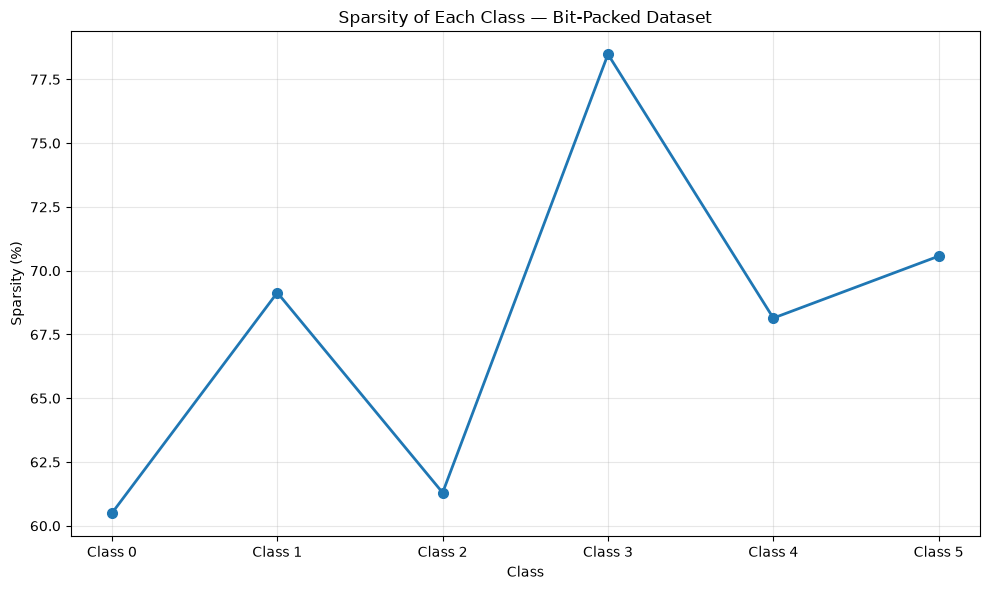

In [17]:
import numpy as np
import matplotlib.pyplot as plt

BITPACKED_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"

# Load bit-packed data
packed = np.load(BITPACKED_FILE)

# Unpack for sparsity calculation
rules = np.unpackbits(
    packed,
    axis=-1,
    bitorder="little"
)[..., :526]

print("=" * 80)
print("BIT-PACKED DATASET — SPARSITY BY CLASS")
print("=" * 80)

sparsities = []
densities = []

for class_id in range(rules.shape[0]):

    class_data = rules[class_id]

    total_bits = class_data.size
    ones = np.count_nonzero(class_data)
    zeros = total_bits - ones

    density = (ones / total_bits) * 100
    sparsity = (zeros / total_bits) * 100

    densities.append(density)
    sparsities.append(sparsity)

    print(
        f"Class {class_id}: "
        f"Total = {total_bits:,} bits | "
        f"Ones = {ones:,} | "
        f"Zeros = {zeros:,} | "
        f"Density = {density:.4f}% | "
        f"Sparsity = {sparsity:.4f}%"
    )

print("=" * 80)

# ---------------------------------------------------------
# Plot sparsity
# ---------------------------------------------------------

classes = [f"Class {i}" for i in range(len(sparsities))]

# Automatically use log scale if the largest value is
# more than 10x the smallest value
use_log = max(sparsities) / min(sparsities) > 10

plt.figure(figsize=(10, 6))

plt.plot(
    classes,
    sparsities,
    marker="o",
    linewidth=2,
    markersize=7
)

plt.xlabel("Class")
plt.ylabel("Sparsity (%)")
plt.title("Sparsity of Each Class — Bit-Packed Dataset")

if use_log:
    plt.yscale("log")
    print("\nUsing LOG scale because there is a large difference.")
else:
    print("\nUsing LINEAR scale.")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

trying bit packed +xor to remove common similarities +lz4 

In [18]:
import numpy as np
import lz4.block
import time

rules = np.load("/home/<user>/iot_dataset/rpi_tm_model/rules.npy")

# 1. Bit-pack
packed = np.packbits(rules, axis=-1, bitorder="little")

# 2. XOR consecutive rows
xor_data = packed.copy()
xor_data[:, 1:, :] ^= packed[:, :-1, :]

data = xor_data.tobytes()

# Warm-up
for _ in range(3):
    lz4.block.compress(data, mode="fast", compression=0, store_size=True)

# 3. Compress
t0 = time.perf_counter()

compressed = lz4.block.compress(
    data,
    mode="fast",
    compression=0,
    store_size=True
)

t1 = time.perf_counter()

# 4. Decompress
decompressed = lz4.block.decompress(compressed)

t2 = time.perf_counter()

# 5. Verify LZ4 round-trip
assert decompressed == data

# 6. Reverse XOR
recovered_xor = np.frombuffer(
    decompressed,
    dtype=np.uint8
).reshape(packed.shape).copy()

for j in range(1, recovered_xor.shape[1]):
    recovered_xor[:, j, :] ^= recovered_xor[:, j-1, :]

# 7. Verify complete reconstruction
assert np.array_equal(recovered_xor, packed)

unpacked = np.unpackbits(
    recovered_xor,
    axis=-1,
    bitorder="little"
)[..., :526]

assert np.array_equal(unpacked, rules)

compress_ms = (t1 - t0) * 1000
decompress_ms = (t2 - t1) * 1000
total_ms = (t2 - t0) * 1000

compressed_mb = len(compressed) / 1_000_000
packed_mb = packed.nbytes / 1_000_000
original_mb = rules.nbytes / 1_000_000

print("=" * 70)
print("BIT-PACKED + XOR + LZ4-0")
print("=" * 70)

print(f"Original size       : {original_mb:.3f} MB")
print(f"Bit-packed size     : {packed_mb:.3f} MB")
print(f"Compressed size     : {compressed_mb:.3f} MB")

print(f"Compression ratio   : {original_mb / compressed_mb:.3f}x")
print(f"Packed → compressed : {packed_mb / compressed_mb:.3f}x")

print(f"Compress time       : {compress_ms:.3f} ms")
print(f"Decompress time     : {decompress_ms:.3f} ms")
print(f"Total time          : {total_ms:.3f} ms")

print(f"Overall reduction   : "
      f"{(1 - compressed_mb / original_mb) * 100:.2f}%")

print("=" * 70)
print("Round-trip: CORRECT")

BIT-PACKED + XOR + LZ4-0
Original size       : 18.936 MB
Bit-packed size     : 2.376 MB
Compressed size     : 1.263 MB
Compression ratio   : 14.996x
Packed → compressed : 1.882x
Compress time       : 5.740 ms
Decompress time     : 1.363 ms
Total time          : 7.103 ms
Overall reduction   : 93.33%
Round-trip: CORRECT


above one didnt work and so im trying rle (run length encoding)+lz4

In [19]:
import numpy as np
import lz4.block
import time
import struct

RULES_FILE = "/home/<user>/iot_dataset/rpi_tm_model/rules.npy"

# ============================================================
# LOAD DATA
# ============================================================

rules = np.load(RULES_FILE)

print("Original shape:", rules.shape)
print("Original dtype:", rules.dtype)


# ============================================================
# 1. BIT-PACK
# ============================================================

packed = np.packbits(
    rules,
    axis=-1,
    bitorder="little"
)

print("Packed shape:", packed.shape)
print("Packed size :", packed.nbytes / 1_000_000, "MB")


# ============================================================
# 2. RLE ENCODER
# ============================================================
#
# We perform RLE on BYTES.
#
# Example:
#
#   AA AA AA AA BB BB CC
#
# becomes:
#
#   (AA,4) (BB,2) (CC,1)
#
# Format:
#
#   [value: 1 byte][count: 4 bytes]
#
# Count is uint32.
#
# ============================================================

def rle_encode(data):

    data = np.asarray(data, dtype=np.uint8).ravel()

    if len(data) == 0:
        return b""

    output = bytearray()

    start = 0

    for i in range(1, len(data) + 1):

        # End of current run
        if i == len(data) or data[i] != data[start]:

            value = int(data[start])
            count = i - start

            # value = 1 byte
            output.append(value)

            # count = 4 bytes
            output.extend(struct.pack("<I", count))

            start = i

    return bytes(output)


# ============================================================
# 3. RLE DECODER
# ============================================================

def rle_decode(encoded, expected_size):

    output = bytearray()

    pos = 0

    while pos < len(encoded):

        value = encoded[pos]
        count = struct.unpack(
            "<I",
            encoded[pos + 1:pos + 5]
        )[0]

        output.extend([value] * count)

        pos += 5

    if len(output) != expected_size:
        raise ValueError(
            f"RLE decode size mismatch: "
            f"{len(output)} != {expected_size}"
        )

    return bytes(output)


# ============================================================
# 4. RLE
# ============================================================

t0 = time.perf_counter()

rle_data = rle_encode(packed)

t1 = time.perf_counter()

rle_encode_ms = (t1 - t0) * 1000

print("\nRLE size:", len(rle_data) / 1_000_000, "MB")
print("RLE encode time:", rle_encode_ms, "ms")


# ============================================================
# 5. LZ4-0 ON RLE DATA
# ============================================================

t2 = time.perf_counter()

compressed = lz4.block.compress(
    rle_data,
    mode="fast",
    compression=0,
    store_size=True
)

t3 = time.perf_counter()

lz4_compress_ms = (t3 - t2) * 1000


# ============================================================
# 6. LZ4 DECOMPRESSION
# ============================================================

t4 = time.perf_counter()

decompressed_rle = lz4.block.decompress(compressed)

t5 = time.perf_counter()

lz4_decompress_ms = (t5 - t4) * 1000


# ============================================================
# 7. RLE DECOMPRESSION
# ============================================================

t6 = time.perf_counter()

recovered_packed_bytes = rle_decode(
    decompressed_rle,
    packed.size
)

t7 = time.perf_counter()

rle_decode_ms = (t7 - t6) * 1000


# ============================================================
# 8. VERIFY PACKED DATA
# ============================================================

recovered_packed = np.frombuffer(
    recovered_packed_bytes,
    dtype=np.uint8
).reshape(packed.shape)

assert np.array_equal(
    recovered_packed,
    packed
)


# ============================================================
# 9. UNPACK
# ============================================================

recovered_rules = np.unpackbits(
    recovered_packed,
    axis=-1,
    bitorder="little"
)[..., :rules.shape[-1]]


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

assert np.array_equal(
    recovered_rules,
    rules
)


# ============================================================
# RESULTS
# ============================================================

original_mb = rules.nbytes / 1_000_000
packed_mb = packed.nbytes / 1_000_000
rle_mb = len(rle_data) / 1_000_000
compressed_mb = len(compressed) / 1_000_000

total_compress_ms = (
    rle_encode_ms +
    lz4_compress_ms
)

total_decompress_ms = (
    lz4_decompress_ms +
    rle_decode_ms
)

total_ms = (
    total_compress_ms +
    total_decompress_ms
)

print("\n")
print("=" * 75)
print("BIT-PACKED + RLE + LZ4-0")
print("=" * 75)

print(f"Original size        : {original_mb:.3f} MB")
print(f"Bit-packed size      : {packed_mb:.3f} MB")
print(f"RLE size             : {rle_mb:.3f} MB")
print(f"Final compressed size: {compressed_mb:.3f} MB")

print("-" * 75)

print(
    f"Overall compression ratio : "
    f"{original_mb / compressed_mb:.3f}x"
)

print(
    f"Packed → final ratio     : "
    f"{packed_mb / compressed_mb:.3f}x"
)

print(
    f"Overall reduction        : "
    f"{(1 - compressed_mb / original_mb) * 100:.2f}%"
)

print("-" * 75)

print(f"RLE encode time      : {rle_encode_ms:.3f} ms")
print(f"LZ4 compress time    : {lz4_compress_ms:.3f} ms")
print(f"Total compression    : {total_compress_ms:.3f} ms")

print(f"LZ4 decompress time  : {lz4_decompress_ms:.3f} ms")
print(f"RLE decode time      : {rle_decode_ms:.3f} ms")
print(f"Total decompression  : {total_decompress_ms:.3f} ms")

print(f"TOTAL TIME           : {total_ms:.3f} ms")

print("-" * 75)

print("Round-trip           : CORRECT")

print("=" * 75)

Original shape: (6, 6000, 526)
Original dtype: uint8
Packed shape: (6, 6000, 66)
Packed size : 2.376 MB

RLE size: 8.026365 MB
RLE encode time: 591.6633754968643 ms


BIT-PACKED + RLE + LZ4-0
Original size        : 18.936 MB
Bit-packed size      : 2.376 MB
RLE size             : 8.026 MB
Final compressed size: 2.546 MB
---------------------------------------------------------------------------
Overall compression ratio : 7.439x
Packed → final ratio     : 0.933x
Overall reduction        : 86.56%
---------------------------------------------------------------------------
RLE encode time      : 591.663 ms
LZ4 compress time    : 6.886 ms
Total compression    : 598.549 ms
LZ4 decompress time  : 2.447 ms
RLE decode time      : 485.594 ms
Total decompression  : 488.042 ms
TOTAL TIME           : 1086.591 ms
---------------------------------------------------------------------------
Round-trip           : CORRECT


In [20]:
import numpy as np
import lz4.block
import time

RULES_FILE = "/home/<user>/iot_dataset/rpi_tm_model/rules.npy"

rules = np.load(RULES_FILE)

print("=" * 80)
print("INDIVIDUAL CLASS: BIT-PACK + LZ4-0")
print("=" * 80)

total_compressed = 0
total_compress_ms = 0
total_decompress_ms = 0

compressed_blocks = []

for cls in range(rules.shape[0]):

    matrix = rules[cls]

    # --------------------------------------------------------
    # Bit-pack this class independently
    # --------------------------------------------------------

    packed = np.packbits(
        matrix,
        axis=-1,
        bitorder="little"
    )

    # --------------------------------------------------------
    # LZ4-0 compression
    # --------------------------------------------------------

    t0 = time.perf_counter()

    compressed = lz4.block.compress(
        packed.tobytes(),
        mode="fast",
        compression=0,
        store_size=True
    )

    t1 = time.perf_counter()

    # --------------------------------------------------------
    # LZ4 decompression
    # --------------------------------------------------------

    decompressed = lz4.block.decompress(compressed)

    t2 = time.perf_counter()

    # --------------------------------------------------------
    # Verify this class
    # --------------------------------------------------------

    recovered_packed = np.frombuffer(
        decompressed,
        dtype=np.uint8
    ).reshape(packed.shape)

    recovered = np.unpackbits(
        recovered_packed,
        axis=-1,
        bitorder="little"
    )[:, :matrix.shape[-1]]

    assert np.array_equal(recovered, matrix)

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    compressed_mb = len(compressed) / 1_000_000
    packed_mb = packed.nbytes / 1_000_000

    compress_ms = (t1 - t0) * 1000
    decompress_ms = (t2 - t1) * 1000
    total_ms = compress_ms + decompress_ms

    total_compressed += len(compressed)
    total_compress_ms += compress_ms
    total_decompress_ms += decompress_ms

    compressed_blocks.append(compressed)

    print(
        f"Class {cls}: "
        f"Packed = {packed_mb:.3f} MB | "
        f"Compressed = {compressed_mb:.3f} MB | "
        f"Compress = {compress_ms:.3f} ms | "
        f"Decompress = {decompress_ms:.3f} ms | "
        f"Total = {total_ms:.3f} ms"
    )


# ============================================================
# TOTAL
# ============================================================

original_mb = rules.nbytes / 1_000_000
packed_mb = (
    rules.shape[0]
    * rules.shape[1]
    * 66
) / 1_000_000

compressed_mb = total_compressed / 1_000_000

total_ms = (
    total_compress_ms +
    total_decompress_ms
)

print()
print("=" * 80)
print("TOTAL: INDIVIDUAL CLASS COMPRESSION")
print("=" * 80)

print(f"Original size          : {original_mb:.3f} MB")
print(f"Bit-packed size        : {packed_mb:.3f} MB")
print(f"Compressed total       : {compressed_mb:.3f} MB")

print("-" * 80)

print(
    f"Original → compressed  : "
    f"{original_mb / compressed_mb:.3f}x"
)

print(
    f"Packed → compressed    : "
    f"{packed_mb / compressed_mb:.3f}x"
)

print(
    f"Overall reduction      : "
    f"{(1 - compressed_mb / original_mb) * 100:.2f}%"
)

print("-" * 80)

print(f"Total compression time : {total_compress_ms:.3f} ms")
print(f"Total decompression    : {total_decompress_ms:.3f} ms")
print(f"TOTAL TIME             : {total_ms:.3f} ms")

print("-" * 80)

print("All classes round-trip : CORRECT")

print("=" * 80)

INDIVIDUAL CLASS: BIT-PACK + LZ4-0
Class 0: Packed = 0.396 MB | Compressed = 0.141 MB | Compress = 0.540 ms | Decompress = 0.109 ms | Total = 0.649 ms
Class 1: Packed = 0.396 MB | Compressed = 0.196 MB | Compress = 0.612 ms | Decompress = 0.117 ms | Total = 0.729 ms
Class 2: Packed = 0.396 MB | Compressed = 0.164 MB | Compress = 0.582 ms | Decompress = 0.104 ms | Total = 0.686 ms
Class 3: Packed = 0.396 MB | Compressed = 0.106 MB | Compress = 0.439 ms | Decompress = 0.119 ms | Total = 0.558 ms
Class 4: Packed = 0.396 MB | Compressed = 0.176 MB | Compress = 0.505 ms | Decompress = 0.115 ms | Total = 0.620 ms
Class 5: Packed = 0.396 MB | Compressed = 0.234 MB | Compress = 0.586 ms | Decompress = 0.112 ms | Total = 0.698 ms

TOTAL: INDIVIDUAL CLASS COMPRESSION
Original size          : 18.936 MB
Bit-packed size        : 2.376 MB
Compressed total       : 1.017 MB
--------------------------------------------------------------------------------
Original → compressed  : 18.621x
Packed → compre

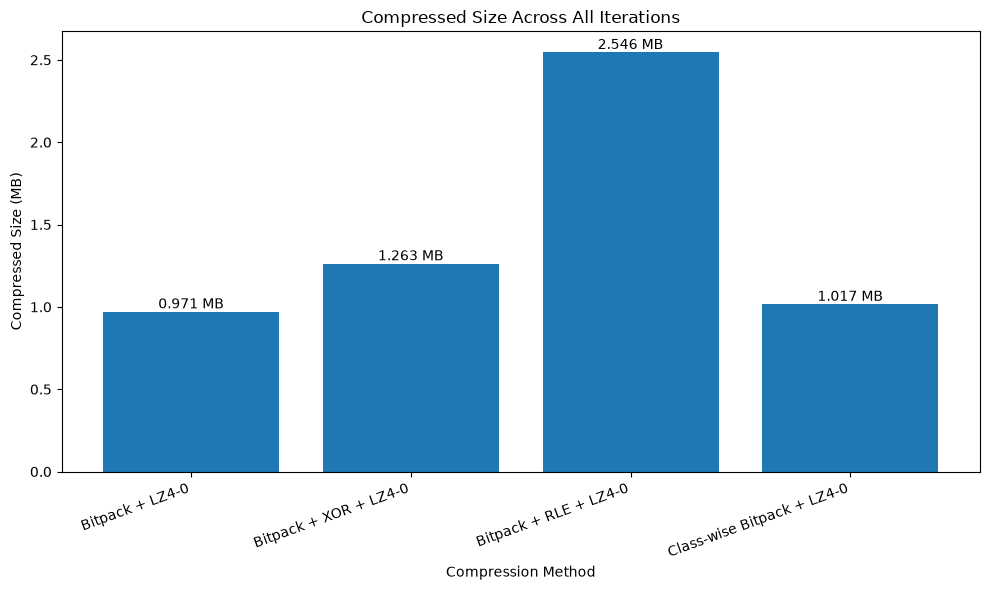

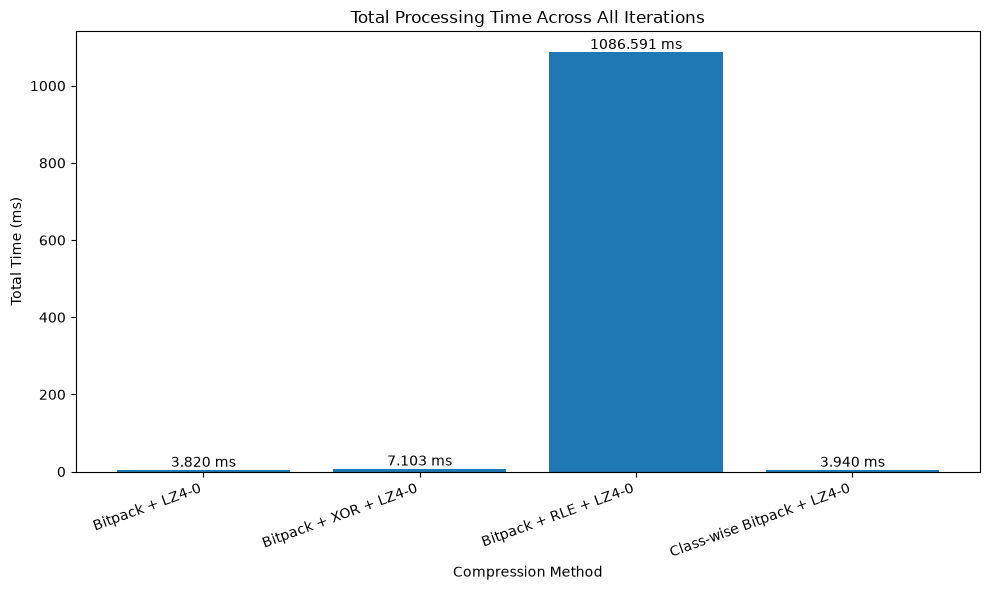

In [21]:
import matplotlib.pyplot as plt

# ============================================================
# DATA FROM ALL ITERATIONS
# ============================================================

methods = [
    "Bitpack + LZ4-0",
    "Bitpack + XOR + LZ4-0",
    "Bitpack + RLE + LZ4-0",
    "Class-wise Bitpack + LZ4-0"
]

compressed_size_mb = [
    0.971,
    1.263,
    2.546,
    1.017
]

total_time_ms = [
    3.820,
    7.103,
    1086.591,
    3.940
]


# ============================================================
# GRAPH 1: COMPRESSED SIZE
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(methods, compressed_size_mb)

plt.title("Compressed Size Across All Iterations")
plt.xlabel("Compression Method")
plt.ylabel("Compressed Size (MB)")

plt.xticks(rotation=20, ha="right")

# Display values above bars
for bar, value in zip(bars, compressed_size_mb):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f} MB",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# ============================================================
# GRAPH 2: TOTAL PROCESSING TIME
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(methods, total_time_ms)

plt.title("Total Processing Time Across All Iterations")
plt.xlabel("Compression Method")
plt.ylabel("Total Time (ms)")

plt.xticks(rotation=20, ha="right")

# Display values above bars
for bar, value in zip(bars, total_time_ms):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()